In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
from sklearn.model_selection import train_test_split

In [3]:
# Cargar el dataset sin anomalías (del Notebook 01)
df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv")

In [ ]:
# Definir variables predictoras (X) y variable objetivo (y) 
# # Transformamos variables categóricas (sexo, escolaridad, formalidad) con get_dummies 

df_reg = pd.get_dummies( 
    df[["ingocup", "hrsocup", "eda", "sex", "cs_p13_1", "p3a", "p3c1", "p3c3"]], 
    columns=["sex", "cs_p13_1", "p3a", "p3c1", "p3c3"], 
    drop_first=True, 
) 
    
X = df_reg.drop(columns=["ingocup"]) 
y = df_reg["ingocup"] 

# Dividir en conjunto de Entrenamiento (80%) y Prueba (20%) 
X_train, X_test, y_train, y_test = train_test_split( 
    X, y, test_size=0.2, random_state=42 
) 


# Entrenar la Regresión Lineal Múltiple 
modelo_rlm = LinearRegression() 
modelo_rlm.fit(X_train, y_train) 

# Evaluación del Modelo (Métricas de Machine Learning) 
y_pred = modelo_rlm.predict(X_test)

In [11]:
print("=== EVALUACIÓN DE REGRESIÓN LINEAL MÚLTIPLE ===") 
print(f"R² (Coeficiente de Determinación): {r2_score(y_test, y_pred):.4f}") 
print(f"MAE (Error Absoluto Medio): ${mean_absolute_error(y_test, y_pred):,.2f} MXN") 
print(f"RMSE (Raíz del Error Cuadrático Medio): ${np.sqrt(mean_squared_error(y_test, y_pred)):,.2f} MXN") 

# Interpretación de Coeficientes (Impacto en el Salario) 
coeficientes = pd.DataFrame( 
    {"Variable": X.columns, "Coeficiente_Pesos": modelo_rlm.coef_} 
).sort_values(by="Coeficiente_Pesos", ascending=False) 

print("\n=== IMPACTO DE CADA VARIABLE EN EL SALARIO ($ MXN) ===") 
print(coeficientes.head(10))

=== EVALUACIÓN DE REGRESIÓN LINEAL MÚLTIPLE ===
R² (Coeficiente de Determinación): 0.2302
MAE (Error Absoluto Medio): $3,493.04 MXN
RMSE (Raíz del Error Cuadrático Medio): $4,646.55 MXN

=== IMPACTO DE CADA VARIABLE EN EL SALARIO ($ MXN) ===
       Variable  Coeficiente_Pesos
9  cs_p13_1_9.0        7834.070550
8  cs_p13_1_8.0        7516.563717
7  cs_p13_1_7.0        5794.200459
5  cs_p13_1_5.0        5434.745711
3  cs_p13_1_3.0        2355.612566
4  cs_p13_1_4.0        1776.342027
6  cs_p13_1_6.0        1208.552451
0       hrsocup         150.365677
1           eda         144.487131
2       sex_2.0        -305.571040


In [ ]:
# Diccionario de traducción de las columnas
diccionario_nombres = {
    # Variables continuas
    "hrsocup": "Horas trabajadas (semanales)",
    "eda": "Edad (años)",
    # Demográficas y laborales (dummies)
    "sex_2.0": "Sexo: Mujer (vs Hombre)",
    "p3a_2": "Condición: Empleo Informal",
    # Niveles Educativos (cs_p13_1)
    "cs_p13_1_3.0": "Escolaridad: Secundaria", 
    "cs_p13_1_4.0": "Escolaridad: Preparatoria / Bachillerato", 
    "cs_p13_1_5.0": "Escolaridad: Carrera Técnica / Normal", 
    "cs_p13_1_6.0": "Escolaridad: Licenciatura", 
    "cs_p13_1_7.0": "Escolaridad: Maestría", 
    "cs_p13_1_8.0": "Escolaridad: Doctorado", 
    "cs_p13_1_9.0": "Escolaridad: No Especificado",
}
# Crear DataFrame con los coeficientes del modelo
df_coef = pd.DataFrame(
    {"Variable": X.columns, "Coeficiente": modelo_rlm.coef_}
).sort_values(by="Coeficiente", ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(
    df_coef["Variable"],
    df_coef["Coeficiente"],
    color=np.where(df_coef["Coeficiente"] >= 0, "#2ca02c", "#d62728"),
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title(
    "Impacto Salarial por variable ($ MXN) - Regresión Lineal Múltiple",
    fontsize=13,
    fontweight="bold",
)

plt.xlabel("Diferencia salarial estimada ($ MXN)")
plt.ylabel("Variable del modelo")
plt.tight_layout()
plt.savefig("../outputs/figures/coeficientes_regresion.png", dpi=300)
plt.show()

SyntaxError: ':' expected after dictionary key (1199548697.py, line 7)

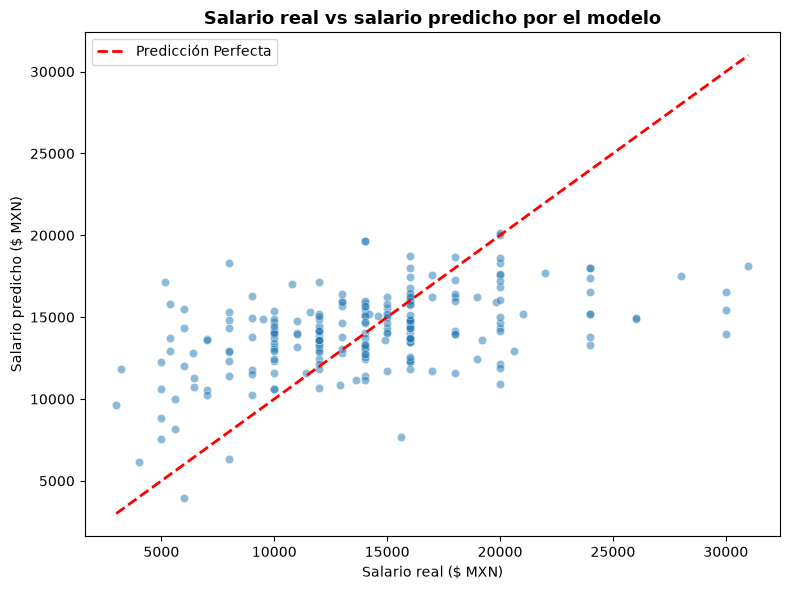

In [14]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, color="#1f77b4")

#Línea ideal de predicción perfecta (y = x)
max_val = max(y_test.max(), y_pred.max())
min_val = min(y_test.min(), y_pred.min())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Predicción Perfecta",
)

plt.title(
    "Salario real vs salario predicho por el modelo",
    fontsize=13,
    fontweight="bold",
)

plt.xlabel("Salario real ($ MXN)")
plt.ylabel("Salario predicho ($ MXN)")
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/figures/real_vs_predicho.png", dpi=300)
plt.show()


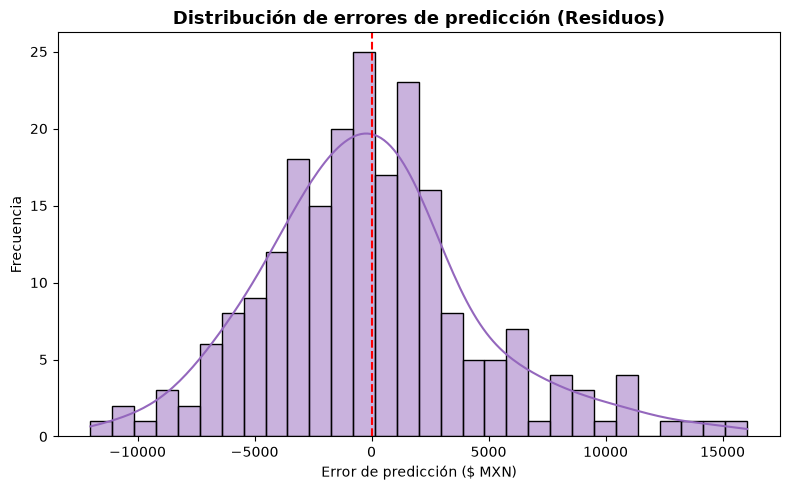

In [15]:
residuos = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.histplot(residuos, kde=True, color="#9467bd", bins=30)
plt.axvline(0, color="red", linestyle="--", linewidth=1.5)
plt.title(
    "Distribución de errores de predicción (Residuos)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Error de predicción ($ MXN)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.savefig("../outputs/figures/distribucion_residuos.png", dpi=300)
plt.show()